# Digital Detective: Feature Extraction Challenge

This notebook runs OpenCV's **ORB (Oriented FAST and Rotated BRIEF)** feature extraction and matching pipeline on two **correlated custom images** of the same teal wireless gaming mouse captured in two different environments:

- **Target Image (`images/mouse_target.jpg`, 768×1024):** The teal wireless mouse resting on a light white/beige desk with an orange alarm clock and cables in the background.
- **Cluttered Scene (`images/mouse_scene.jpg`, 576×1024):** The **same** teal wireless mouse rotated ~65°–70° and tilted on a dark Lenovo IdeaPad Gaming laptop keyboard under dimmer/cooler indoor lighting, with a busy WhatsApp Web window and Windows taskbar above it.

> **Note for Google Colab users:** Clone the repository (`!git clone <repo-url> && %cd <repo-name>`) or upload `images/mouse_target.jpg` and `images/mouse_scene.jpg` into an `images/` folder before running the cells below.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Bounding boxes (x_min, y_min, x_max, y_max) for the teal mouse in each image
TARGET_ROI_BOX = (225, 390, 525, 745)
TARGET_EVAL_BOX = (235, 405, 515, 735)
SCENE_EVAL_BOX = (190, 480, 485, 665)
TARGET_MOUSE_POLY = np.array(
    [[290, 410], [425, 410], [475, 480], [495, 620], [465, 705], [355, 710], [295, 670], [235, 555], [230, 455]],
    dtype=np.int32,
)


def show_img(title, img):
    """Display an OpenCV BGR image cleanly in Jupyter/Colab."""
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=13, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


def in_box(pt, box):
    """Check whether 2D point (x, y) lies within (x_min, y_min, x_max, y_max)."""
    return box[0] <= pt[0] <= box[2] and box[1] <= pt[1] <= box[3]


def select_distinct_keypoints(keypoints, k=5, min_dist=52.0, region_poly=None):
    """Pick top-k strongest keypoints separated by at least min_dist pixels."""
    ranked = sorted(keypoints, key=lambda kp: kp.response, reverse=True)
    selected = []
    for kp in ranked:
        if region_poly is not None and cv2.pointPolygonTest(region_poly, kp.pt, False) < 0:
            continue
        if all(np.hypot(kp.pt[0] - s.pt[0], kp.pt[1] - s.pt[1]) >= min_dist for s in selected):
            selected.append(kp)
            if len(selected) == k:
                break
    return selected

## Step 1: Load and Prepare Images
Load both correlated images from `images/` and convert them to grayscale (`cv2.COLOR_BGR2GRAY`), since ORB detects corner keypoints and computes binary intensity comparisons on single-channel luminance values.

Images successfully loaded and converted to grayscale.
Target image shape: 768x1024
Scene image shape : 576x1024


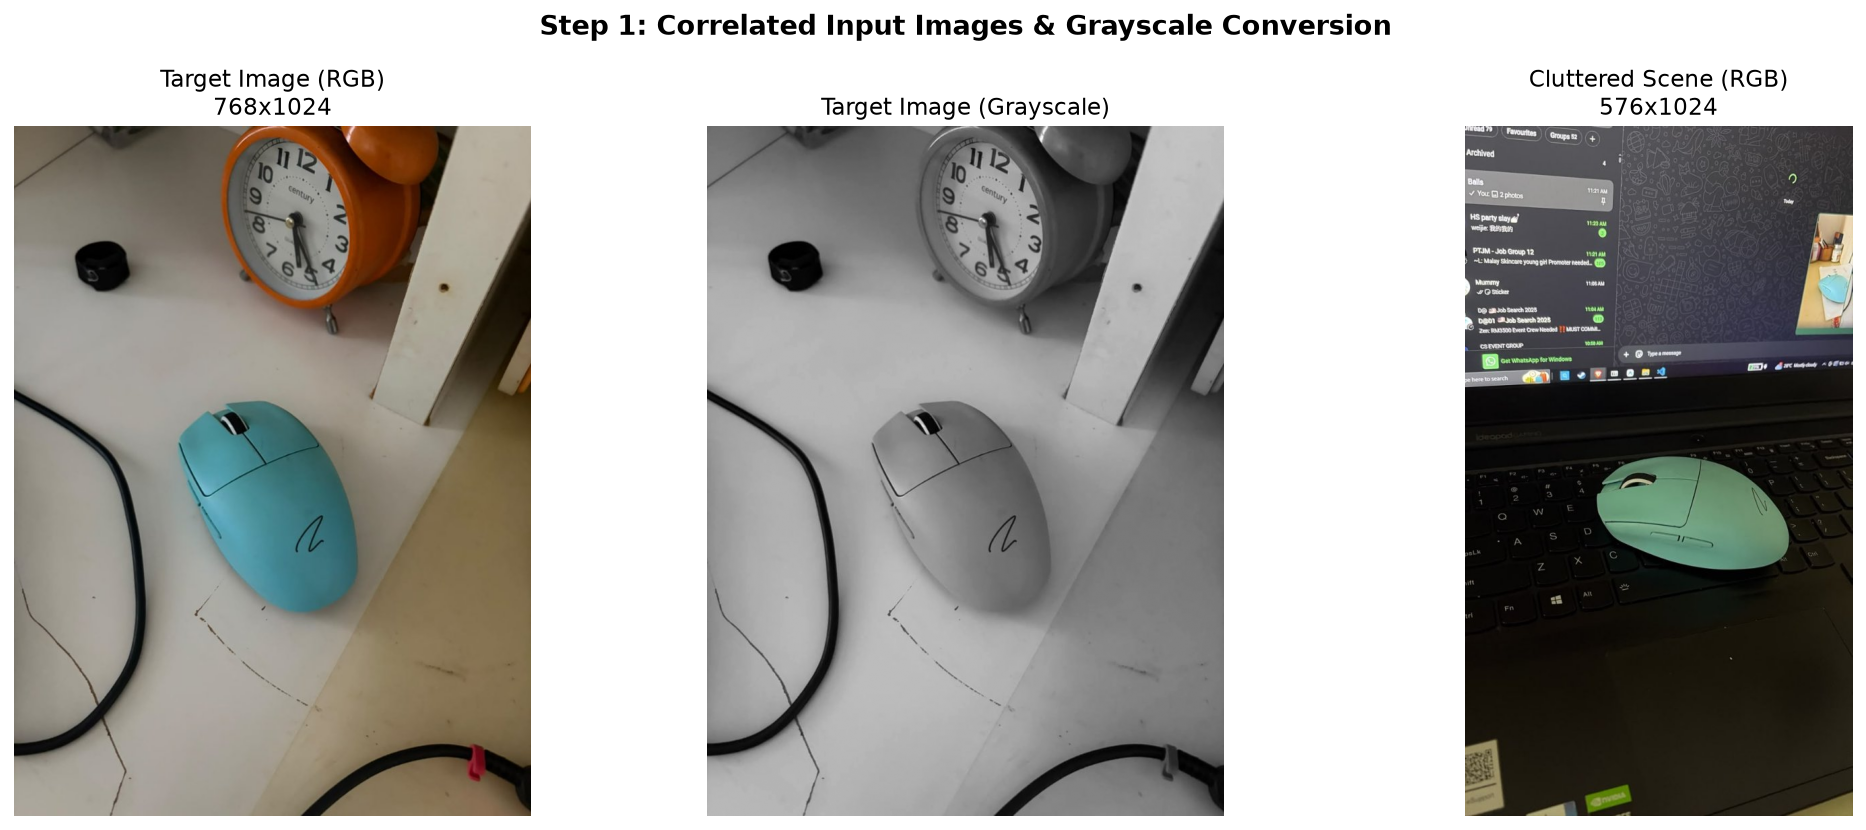

In [3]:
img_target = cv2.imread("images/mouse_target.jpg")
img_scene = cv2.imread("images/mouse_scene.jpg")

if img_target is None or img_scene is None:
    raise FileNotFoundError("Please ensure images/mouse_target.jpg and images/mouse_scene.jpg exist.")

gray_target = cv2.cvtColor(img_target, cv2.COLOR_BGR2GRAY)
gray_scene = cv2.cvtColor(img_scene, cv2.COLOR_BGR2GRAY)

print("Images successfully loaded and converted to grayscale.")
print(f"Target image shape: {img_target.shape[1]}x{img_target.shape[0]}")
print(f"Scene image shape : {img_scene.shape[1]}x{img_scene.shape[0]}")

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes[0].imshow(cv2.cvtColor(img_target, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Target Image (RGB)\n{img_target.shape[1]}x{img_target.shape[0]}")
axes[0].axis("off")

axes[1].imshow(gray_target, cmap="gray")
axes[1].set_title("Target Image (Grayscale)")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(img_scene, cv2.COLOR_BGR2RGB))
axes[2].set_title(f"Cluttered Scene (RGB)\n{img_scene.shape[1]}x{img_scene.shape[0]}")
axes[2].axis("off")

plt.suptitle("Step 1: Correlated Input Images & Grayscale Conversion", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Step 2A: Baseline Check (Unmasked Full Images, `nfeatures=500`)
Before isolating the target mouse, we run the exact default lab settings (`cv2.ORB_create(nfeatures=500)`) across the unmasked images. Because the orange alarm clock numbers (Target) and the WhatsApp Web chat + Windows taskbar (Scene) contain dense high-contrast text edges, they consume almost the entire 500-keypoint budget and overwhelm the matte teal mouse.

Baseline Target Keypoints: 500 (on mouse: 89, background: 411)
Baseline Scene Keypoints : 500 (on mouse: 6, background: 494)
Baseline Total Matches   : 97
Baseline Top-20 Mouse Hits: 2/20 (10%)


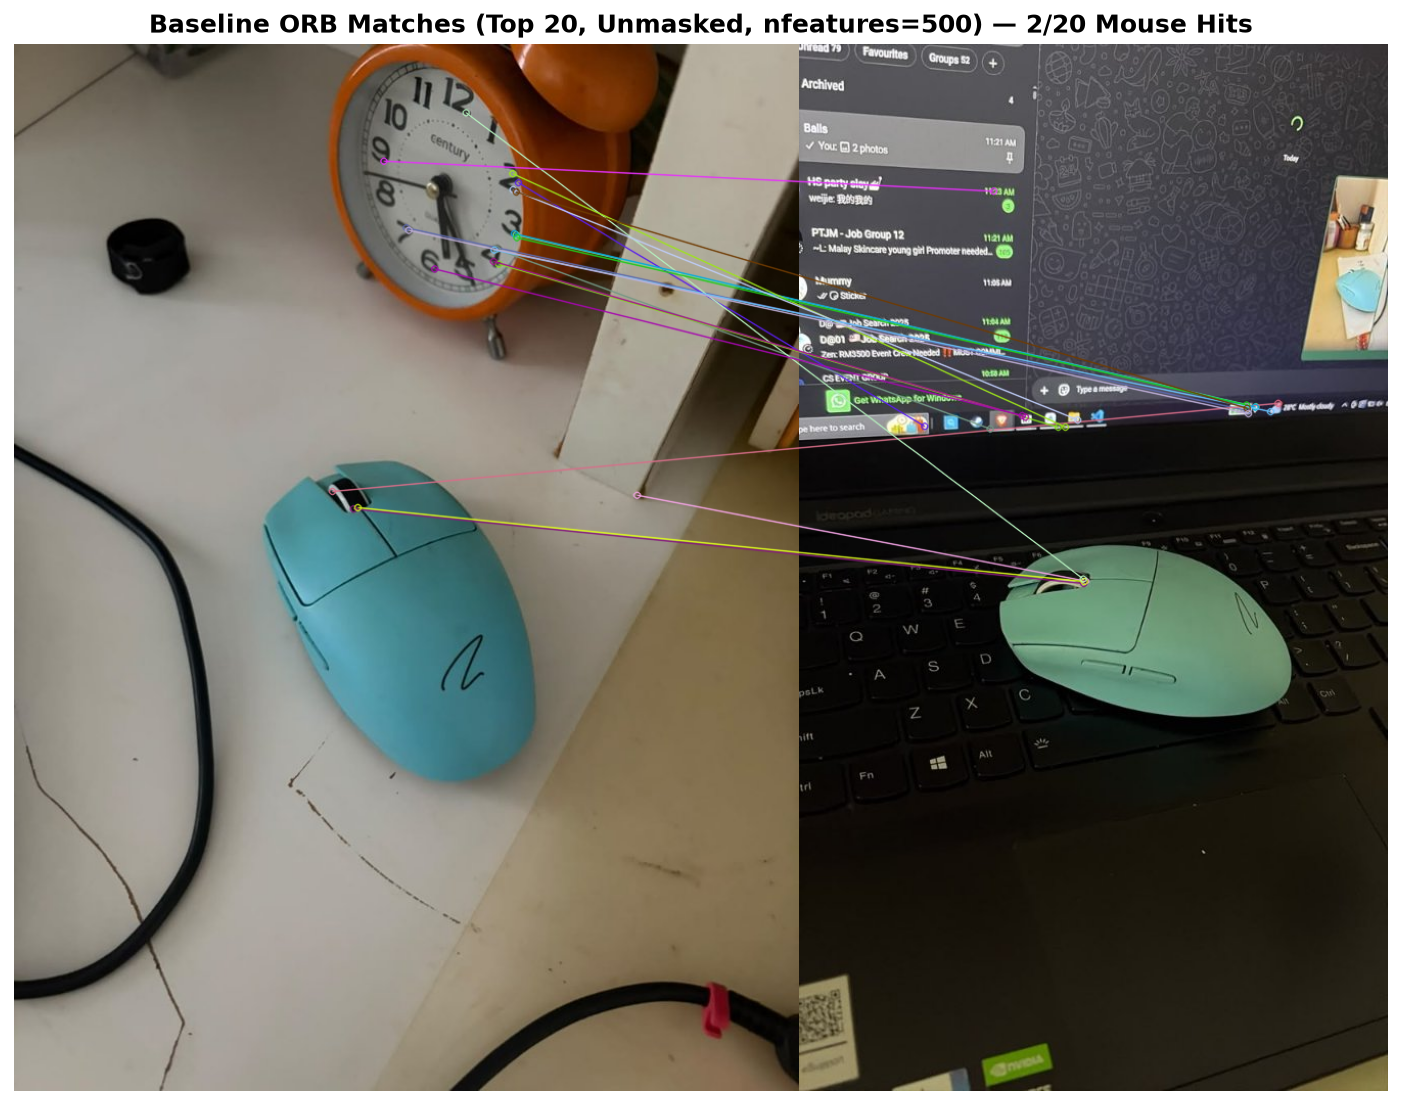

In [5]:
orb_base = cv2.ORB_create(nfeatures=500)
kp_t_base, des_t_base = orb_base.detectAndCompute(gray_target, None)
kp_s_base, des_s_base = orb_base.detectAndCompute(gray_scene, None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches_base = sorted(bf.match(des_t_base, des_s_base), key=lambda x: x.distance)

t_mouse_kp = sum(1 for k in kp_t_base if in_box(k.pt, TARGET_EVAL_BOX))
s_mouse_kp = sum(1 for k in kp_s_base if in_box(k.pt, SCENE_EVAL_BOX))
base_top20_hits = sum(
    1 for m in matches_base[:20]
    if in_box(kp_t_base[m.queryIdx].pt, TARGET_EVAL_BOX)
    and in_box(kp_s_base[m.trainIdx].pt, SCENE_EVAL_BOX)
)

print(f"Baseline Target Keypoints: {len(kp_t_base)} (on mouse: {t_mouse_kp}, background: {len(kp_t_base) - t_mouse_kp})")
print(f"Baseline Scene Keypoints : {len(kp_s_base)} (on mouse: {s_mouse_kp}, background: {len(kp_s_base) - s_mouse_kp})")
print(f"Baseline Total Matches   : {len(matches_base)}")
print(f"Baseline Top-20 Mouse Hits: {base_top20_hits}/20 ({100 * base_top20_hits / 20:.0f}%)")

img_base_matches = cv2.drawMatches(
    img_target, kp_t_base,
    img_scene, kp_s_base,
    matches_base[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)
show_img(f"Baseline ORB Matches (Top 20, Unmasked, nfeatures=500) — {base_top20_hits}/20 Mouse Hits", img_base_matches)

## Step 2B: Focused Target ROI & Tuned ORB Feature Extraction
To prevent background objects on the desk from hijacking target clues—mirroring how `Cup.jpeg` isolates the target object while keeping the full 1024 px height aligned with the scene—we apply a binary target ROI mask (`mask_target[390:745, 225:525] = 255`), leave the scene completely **unmasked**, and increase ORB sensitivity (`nfeatures=5000, fastThreshold=10`) so subtle matte edges and corners on the mouse are captured.

Target ROI keypoints: 866
Scene keypoints     : 4361 (on mouse: 502)
  Feature 1: pt=(309.6, 432.0), response=0.000825
  Feature 2: pt=(285.0, 546.0), response=0.000648
  Feature 3: pt=(440.0, 627.0), response=0.000236
  Feature 4: pt=(373.0, 501.0), response=0.000224
  Feature 5: pt=(245.0, 471.0), response=0.000081


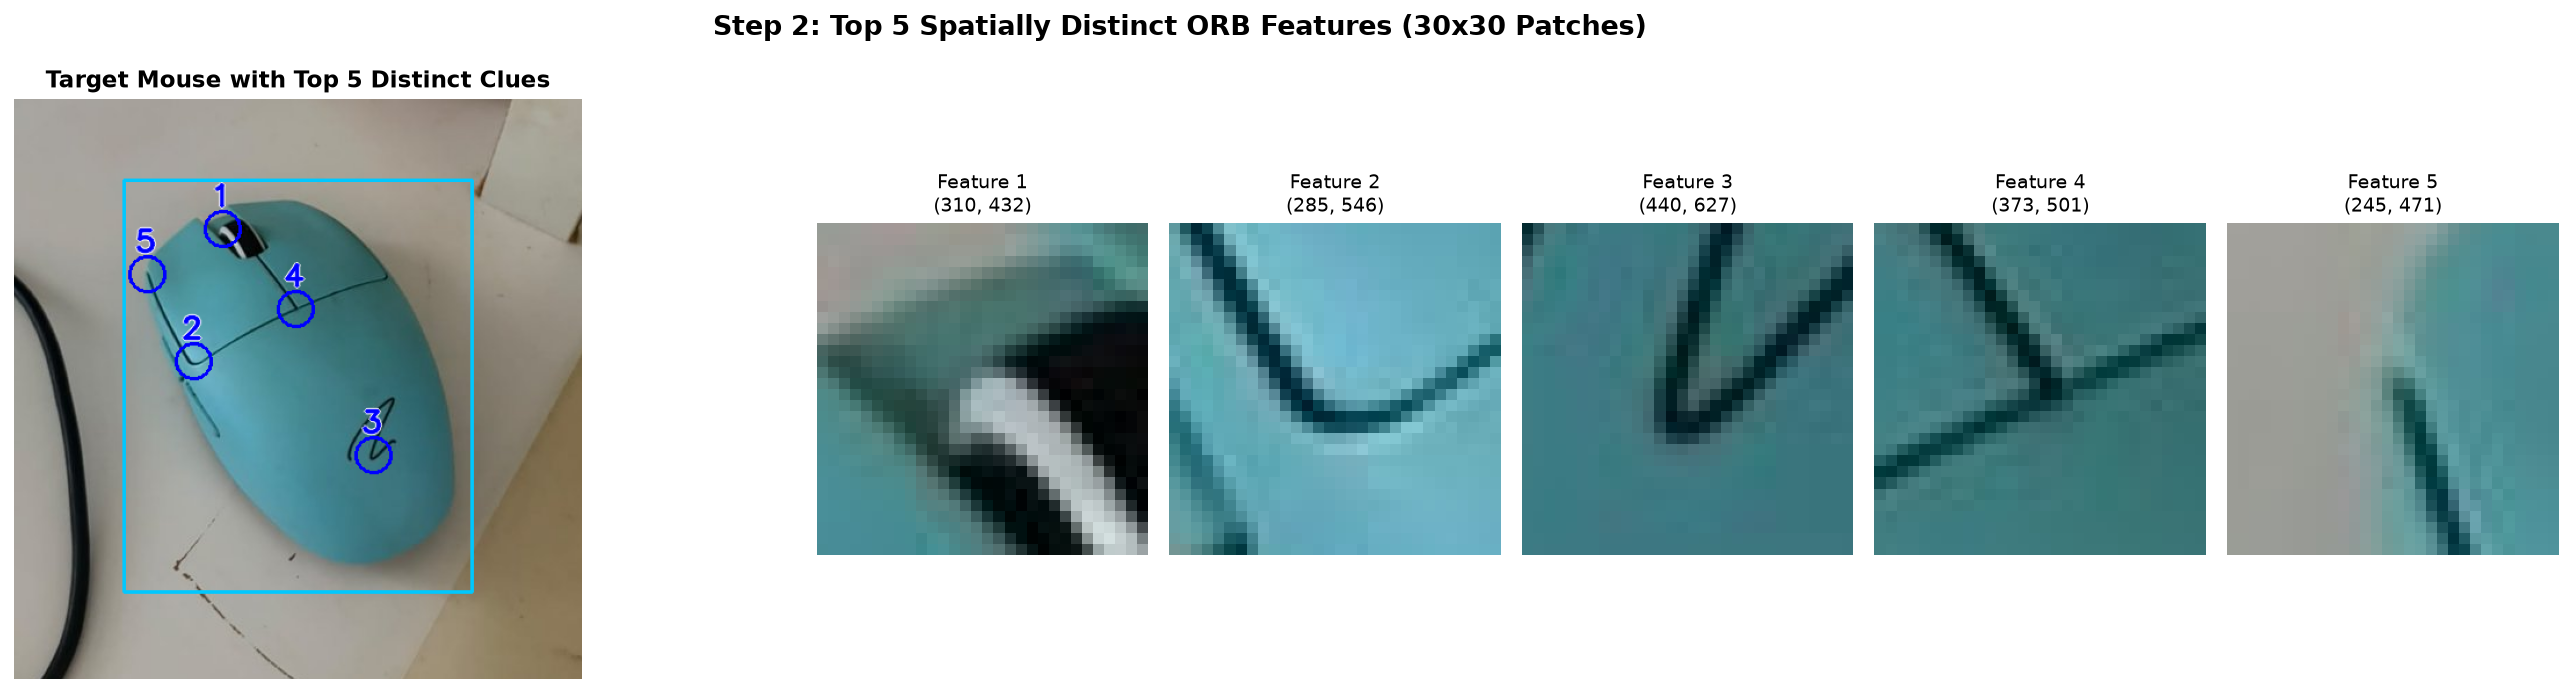

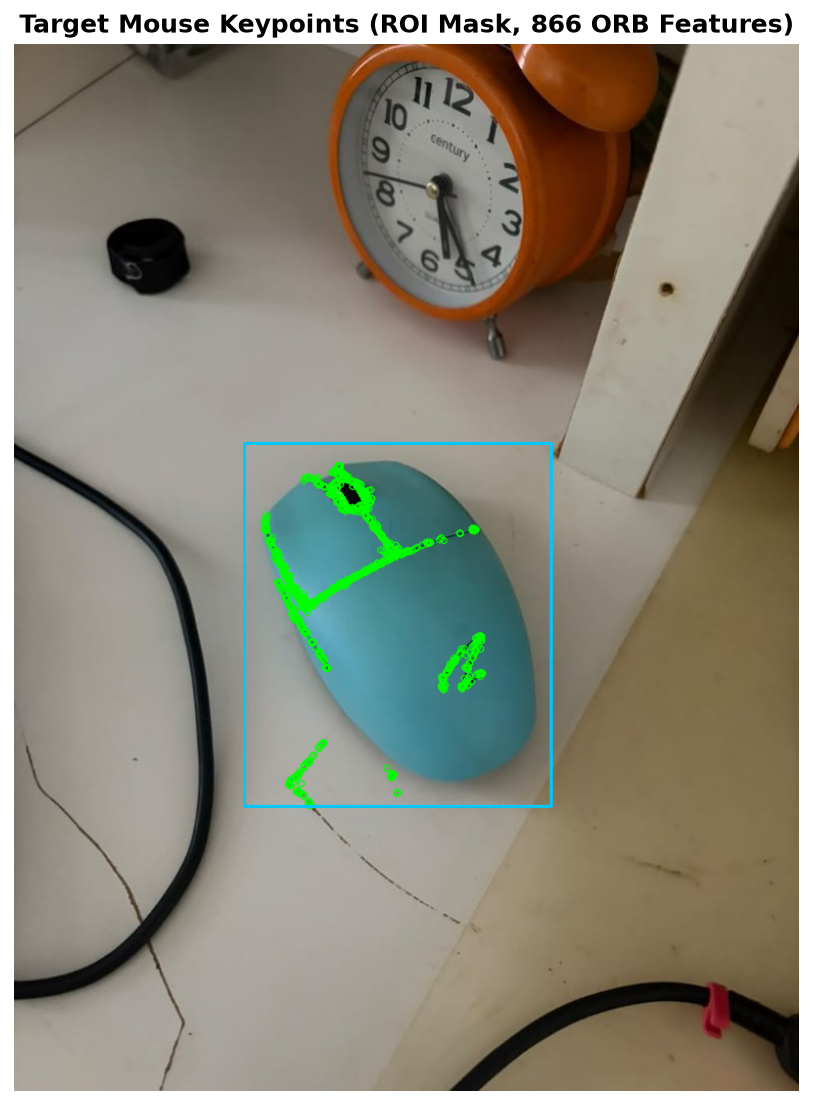

In [7]:
mask_target = np.zeros(gray_target.shape, dtype=np.uint8)
x1, y1, x2, y2 = TARGET_ROI_BOX
mask_target[y1:y2, x1:x2] = 255

orb = cv2.ORB_create(nfeatures=5000, fastThreshold=10)
kp_target, des_target = orb.detectAndCompute(gray_target, mask_target)
kp_scene, des_scene = orb.detectAndCompute(gray_scene, None)

s_tuned_mouse_kp = sum(1 for k in kp_scene if in_box(k.pt, SCENE_EVAL_BOX))
print(f"Target ROI keypoints: {len(kp_target)}")
print(f"Scene keypoints     : {len(kp_scene)} (on mouse: {s_tuned_mouse_kp})")

# Visualize the top 5 spatially distinct clues on the mouse + 30x30 patches
top5_kp = select_distinct_keypoints(kp_target, k=5, min_dist=52.0, region_poly=TARGET_MOUSE_POLY)
fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={"width_ratios": [3, 1, 1, 1, 1, 1]})

img_target_annotated = img_target.copy()
cv2.rectangle(img_target_annotated, (x1, y1), (x2, y2), (255, 200, 0), 2)
offset = 15

for i, kp in enumerate(top5_kp):
    x, y = int(round(kp.pt[0])), int(round(kp.pt[1]))
    print(f"  Feature {i+1}: pt=({kp.pt[0]:.1f}, {kp.pt[1]:.1f}), response={kp.response:.6f}")

    cv2.circle(img_target_annotated, (x, y), offset, (255, 0, 0), 2)
    label_pos = (x - 10, max(25, y - 20))
    cv2.putText(img_target_annotated, str(i + 1), label_pos, cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 255, 255), 4, cv2.LINE_AA)
    cv2.putText(img_target_annotated, str(i + 1), label_pos, cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 0, 0), 2, cv2.LINE_AA)

    patch = img_target[
        max(0, y - offset) : min(img_target.shape[0], y + offset),
        max(0, x - offset) : min(img_target.shape[1], x + offset),
    ]
    axes[i + 1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i + 1].set_title(f"Feature {i + 1}\n({x}, {y})", fontsize=10)
    axes[i + 1].axis("off")

axes[0].imshow(cv2.cvtColor(img_target_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_xlim(130, 620)
axes[0].set_ylim(820, 320)
axes[0].set_title("Target Mouse with Top 5 Distinct Clues", fontsize=12, fontweight="bold")
axes[0].axis("off")

plt.suptitle("Step 2: Top 5 Spatially Distinct ORB Features (30x30 Patches)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

img_target_kp = cv2.drawKeypoints(img_target, kp_target, None, color=(0, 255, 0), flags=0)
cv2.rectangle(img_target_kp, (x1, y1), (x2, y2), (255, 200, 0), 2)
show_img(f"Target Mouse Keypoints (ROI Mask, {len(kp_target)} ORB Features)", img_target_kp)

## Step 3 & 4: Match Features and Analyze the Results
We compare the 256-bit binary descriptors between the target mouse and the cluttered laptop scene using `cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)`, sort matches by Hamming distance (lower = stronger similarity), and draw the Top 20 matches.

Total features matched: 195
Top-20 distance range : 24.0 - 46.0
Top-20 mouse hits     : 14/20 (70%) | False background matches: 6/20
All mouse hits        : 75/195

  # 1 | dist=24.0 | target=(339.6, 454.8) -> scene=(283.0, 523.0) [MOUSE]
  # 2 | dist=27.0 | target=(344.2, 514.3) -> scene=(342.1, 537.1) [MOUSE]
  # 3 | dist=28.0 | target=(335.5, 456.5) -> scene=(280.0, 527.0) [MOUSE]
  # 4 | dist=31.0 | target=(344.2, 454.1) -> scene=(283.2, 520.8) [MOUSE]
  # 5 | dist=32.0 | target=(343.9, 454.5) -> scene=(283.0, 521.0) [MOUSE]
  # 6 | dist=34.0 | target=(324.0, 525.6) -> scene=(333.8, 566.1) [MOUSE]
  # 7 | dist=35.0 | target=(293.8, 589.2) -> scene=( 49.0, 358.0) [BACKGROUND]
  # 8 | dist=36.0 | target=(334.4, 519.6) -> scene=(340.4, 541.1) [MOUSE]
  # 9 | dist=39.0 | target=(420.0, 620.4) -> scene=(278.7, 525.0) [MOUSE]
  #10 | dist=40.0 | target=(420.0, 630.0) -> scene=(282.0, 520.5) [MOUSE]
  #11 | dist=40.0 | target=(447.9, 473.0) -> scene=(367.0, 620.0) [MOUSE]
  #12 | dist=41.

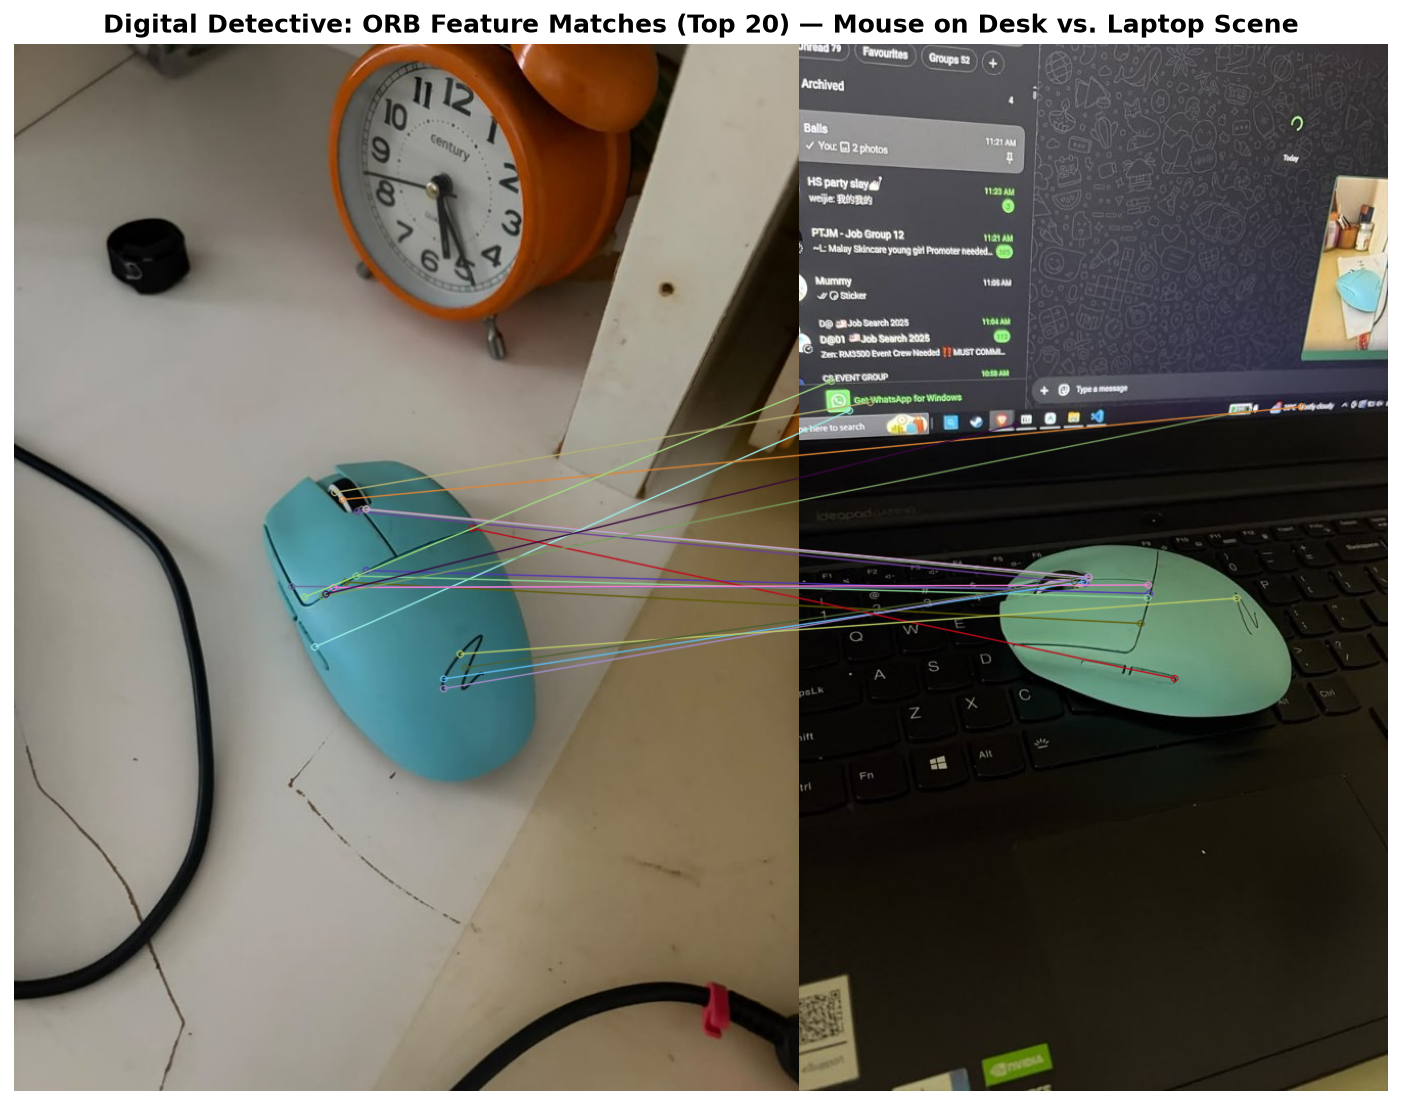

In [9]:
matches = sorted(bf.match(des_target, des_scene), key=lambda x: x.distance)

top20_hits = sum(1 for m in matches[:20] if in_box(kp_scene[m.trainIdx].pt, SCENE_EVAL_BOX))
all_hits = sum(1 for m in matches if in_box(kp_scene[m.trainIdx].pt, SCENE_EVAL_BOX))

print(f"Total features matched: {len(matches)}")
print(f"Top-20 distance range : {matches[0].distance:.1f} - {matches[19].distance:.1f}")
print(f"Top-20 mouse hits     : {top20_hits}/20 ({100 * top20_hits / 20:.0f}%) | False background matches: {20 - top20_hits}/20")
print(f"All mouse hits        : {all_hits}/{len(matches)}\n")

for idx, m in enumerate(matches[:20], start=1):
    pt1 = kp_target[m.queryIdx].pt
    pt2 = kp_scene[m.trainIdx].pt
    label = "MOUSE" if in_box(pt2, SCENE_EVAL_BOX) else "BACKGROUND"
    print(f"  #{idx:2d} | dist={m.distance:4.1f} | target=({pt1[0]:5.1f}, {pt1[1]:5.1f}) -> scene=({pt2[0]:5.1f}, {pt2[1]:5.1f}) [{label}]")

img_matches = cv2.drawMatches(
    img_target, kp_target,
    img_scene, kp_scene,
    matches[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)

show_img("Digital Detective: ORB Feature Matches (Top 20) — Mouse on Desk vs. Laptop Scene", img_matches)

## Reflection & Discussion

### 1. Feature Effectiveness — Which feature was the most useful for finding the object quickly, and why did it work so well?
The **recessed black-and-white scroll wheel** (achieving the lowest Hamming distance of **24.0** at `target=(339.6, 454.8) -> scene=(283.0, 523.0)`, plus 4 of the top 5 best matches) and the **left/right click button T-junction seam** (`dist=27.0`, `target=(344.2, 514.3) -> scene=(342.1, 537.1)`) were by far the most useful features for locating the mouse quickly and reliably.

- **High local intensity contrast:** The white scroll-wheel rim sandwiched against the dark wheel recess and dark center seam produces sharp, steep grayscale brightness gradients—unlike the smooth, matte teal plastic shell, which yields almost zero FAST corner responses.
- **Distinctive corner & junction geometry:** The button T-junction and scroll-wheel corners create well-defined intersecting edges that appear uniquely on the mouse, giving ORB both **distinctiveness** (unique 256-bit binary descriptor fingerprints) and **repeatability** across both scenes.

---

### 2. Ambiguous Features — Which features were ambiguous or accidentally matched the wrong object?
Our two experimental stages revealed two clear sources of false positives ("hallucinated matches"):

1. **High-contrast background clutter overwhelming the budget (Unmasked Baseline, `nfeatures=500`):**
   - Without an ROI mask on the target image, **411 / 500** target keypoints landed on the orange alarm clock numbers and desk cables, while **494 / 500** scene keypoints landed on the WhatsApp Web chat list and Windows taskbar (leaving only **6** keypoints on the mouse in the scene).
   - As a result, **18 / 20 (90%)** of the Top 20 baseline matches connected alarm-clock numerals and desk lines to WhatsApp text/taskbar icons, with only **2 / 20** matching the mouse.
2. **Local edge & dark-curve ambiguity (Target ROI Mask, `nfeatures=5000, fastThreshold=10`):**
   - Even after isolating the target mouse (`866` keypoints) and finding **14 / 20 (70%)** true mouse hits across the scroll wheel, button T-junction, front-left button edge (`#12`, `dist=41.0`), and stylized palm logo (`#14`, `dist=44.0`), **6 / 20 (30%)** of the Top 20 matches were still false positives (`#7`, `#15`, `#16`, `#17`, `#19`, `#20`, distances `35.0–46.0`) connecting simple dark seam/outer-edge segments on the mouse to high-contrast UI icons along the Windows taskbar and WhatsApp Web panel.
   - In addition, matches `#9`, `#10`, and `#18` linked strokes of the dark stylized palm logo in the target image (`(420, 620)`, `(420, 630)`, `(441, 609)`) to the dark scroll-wheel rim in the scene (`~(279, 525)`), because small local grayscale patches (`31×31` pixels) around thin dark curves look mathematically similar when evaluated independently without global geometric context.
   - **How to filter these:** Applying **Lowe's Ratio Test** (`knnMatch` with `k=2`, keeping `m.distance < 0.80 * n.distance`) discards ambiguous descriptors with close runners-up, and fitting a **RANSAC Homography** enforces global spatial consistency so isolated UI/background outliers are rejected.

---

### 3. Robustness Challenge — When the object is rotated, or the lighting is different, do the features still work?
Our two photos directly stress-test three real-world transformations simultaneously: **~65°–70° in-plane rotation**, **oblique 3D perspective tilt**, **dimmer/cooler lighting**, and **background contrast inversion** (bright white desk vs. black laptop keyboard).

- **Why ORB still succeeded (`14 / 20` Top-20 mouse hits, `75 / 195` total mouse hits):**
  - **Rotation invariance (oFAST + rBRIEF):** ORB computes each keypoint's dominant orientation angle $\theta$ from the patch's **intensity centroid** and steers its 256-bit BRIEF pairwise comparison pattern by $\theta$, allowing the scroll wheel, button T-junction, and palm logo to match reliably despite the ~65°–70° rotation.
  - **Illumination resilience:** rBRIEF encodes *relative* pairwise pixel intensity signs ($I(p_A) < I(p_B) \rightarrow 0\text{ or }1$) rather than raw RGB values, making descriptors resilient to uniform brightness shifts and color-temperature changes (warm desk light vs. cool laptop screen glow).
  - **Moderate scale invariance:** ORB builds a multi-scale image pyramid, handling the slight camera-distance difference between the two photos.
- **Where robustness degraded (and why):**
  - **Outer-boundary contrast reversal:** On the white desk, the teal mouse is darker than its background (`teal < white`); on the black laptop keyboard, the teal mouse is brighter than its background (`teal > black`). This flips the gradient direction along the mouse's outer silhouette, breaking edge/corner matches along the perimeter while **internal features** (scroll wheel, button seams, printed palm logo) remained consistent against the teal shell.
  - **3D out-of-plane perspective foreshortening:** Looking more from the side in the laptop photo compresses the sloped palm logo and button curvature unevenly, which ORB (not affine-invariant) handles less cleanly than pure 2D rotation.
  - **Low-contrast matte shell:** Under dimmer indoor lighting, OpenCV's default `fastThreshold=20` missed subtle internal mouse seams until lowered to `fastThreshold=10` with `nfeatures=5000`.